In [120]:
# 1. Libraries
from pathlib import Path
import json
import h5py
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display, HTML
import base64
from tqdm.auto import tqdm
from matplotlib.colors import LogNorm
from detector_io import load_detector_image

# Choose the detector before running the notebook.
detector = "CMOS"                # "CMOS" or "MCP"

In [121]:
# 2. Average pixels inside bins (empty bins stay NaN)
def bin_average(coordinate, image, edges, valid):
    count = np.histogram(coordinate[valid], bins=edges)[0]
    total = np.histogram(coordinate[valid], bins=edges, weights=image[valid])[0]
    mean = np.full(len(edges) - 1, np.nan)
    np.divide(total, count, out=mean, where=count > 0)
    return mean, count

def load_image(index):
    return load_detector_image(index, detector, input_folder, image_key)

In [ ]:
# 3. Folders and detector channel
input_folder = Path("raw") / detector
output_folder = Path("output") / detector.lower()
output_folder.mkdir(parents=True, exist_ok=True)
image_key = "data_22"             # observed CMOS channel, not scalar data_20

# Optional dark scan: same detector settings and exposure as the signal scans.
# Set a scan number (e.g. 15), or None to disable. Rerun from here after editing.
dark_scan_index = 416 if detector == "CMOS" else None
dark_image = None
if dark_scan_index is not None:
    dark_image = load_image(dark_scan_index)
    print("Loaded dark scan:", dark_scan_index)
# Subtraction uses the mean dark exposure, without exposure-time scaling.
# Negative corrected intensities are retained; log plots show positive values only.

# MCP integers are zero-based indices; filenames are also accepted by load_image.
# Set scan lists/fields for your MCP acquisition before analyzing a series.
if detector == "MCP":
    for index, path in enumerate(sorted(input_folder.glob("*_TDC_2D_*.txt"))):
        print(index, path.name)


In [ ]:
# 3b. Choose one image and adjust its center BEFORE loading the series.
# Edit center_x/center_y and rerun this cell until the circles match the rings.
center_image_index = 16 if detector == "CMOS" else 0 if detector == "CMOS" else 0
center_image = load_image(center_image_index)
if dark_image is not None:
    center_image = center_image - dark_image
center_x = 1030   # column; enter your center here
center_y = 1010   # row; enter your center here
circle_radii = [100, 300, 500, 700, 900]     # original pixels

# Same Paint mask as the analysis. None explicitly disables it.
center_mask_path = output_folder / "beamstop_mask.png"
center_mask = np.zeros(center_image.shape, dtype=bool)
if center_mask_path is not None:
    with Image.open(center_mask_path) as file:
        rgba = np.asarray(file.convert("RGBA"))
    center_mask = np.flipud((rgba[..., 0] >= 200) & (rgba[..., 1] < 100) &
                            (rgba[..., 2] < 100) & (rgba[..., 3] > 0))
center_mi, center_ma = np.nanpercentile(
    center_image[~center_mask & np.isfinite(center_image)], [1, 90])
center_figure, ax = plt.subplots(figsize=(10, 9), constrained_layout=True)
center_artist = ax.imshow(center_image, origin="lower", cmap="magma",
                          vmin=center_mi, vmax=center_ma)
ax.plot(center_x, center_y, "+", color="cyan", markersize=14)
for r in circle_radii:
    ax.add_patch(plt.Circle((center_x, center_y), r, fill=False, color="cyan", linewidth=0.8))
ax.set_xlim(-0.5, center_image.shape[1] - 0.5)
ax.set_ylim(-0.5, center_image.shape[0] - 0.5)
ax.set(title=f"Scan {center_image_index}: center ({center_x:g}, {center_y:g})",
       xlabel="Column (px)", ylabel="Row (px)")
center_figure.colorbar(center_artist, ax=ax, label="Intensity (1–90 percentile)")
plt.show()

In [ ]:
# 4. File indices and corresponding fields — one field per file


#energy
ims = np.arange(376,415)
fields = np.linspace(480, 490, ims.size)    # EXAMPLE: replace with your actual fields
field_unit = "eV"                # edit if needed; these fields are user supplied



#22 deg
ims = np.arange(16, 136)
#45 deg
ims = np.arange(136, 256)
#0 deg
ims = np.arange(256, 376)

#22 deg-after
ims = np.arange(444, 504)

fields = np.linspace(300, -300, ims.size)    # EXAMPLE: replace with your actual fields
field_unit = "mT"                # edit if needed; these fields are user supplied




# For ten values fields=np.arange(50, 0, -5), choose ten matching scan indices.
if len(ims) != len(fields):
    raise ValueError("Provide exactly one field value per file index")

# Filename range follows np.arange: the upper endpoint is excluded.
output_range = f"{ims[0]}-{ims[-1] + 1}"  # e.g. 16-136 for scans 16–135

# The last uncommented input block is active (currently energy).
scan_label = "Energy" if field_unit == "eV" else "Field"
radial_folder = output_folder / "radial"
azimuthal_folder = output_folder / "azimuthal"
radial_folder.mkdir(parents=True, exist_ok=True)
azimuthal_folder.mkdir(parents=True, exist_ok=True)

In [ ]:
# 5. Load images; failed files keep their scan/field position as NaNs.
images = []
failed_indices = []
image_shape = None
for index in tqdm(ims, desc="Loading scans", unit="scan"):
    try:
        image = load_image(index)
        if image.ndim != 2 or (image_shape is not None and image.shape != image_shape):
            raise ValueError("Image shape does not match the other scans")
        if dark_image is not None:
            image = image - dark_image
        image_shape = image.shape
        images.append(image)
        print(index, image.shape)
    except (OSError, KeyError, ValueError, IndexError) as error:
        images.append(None)
        failed_indices.append(int(index))
        print(f"Scan {index}: using NaNs ({error})")

if image_shape is None:
    raise ValueError("No image could be loaded to determine the detector shape")
# Shared blank array keeps missing scans from consuming unnecessary memory.
blank_image = np.full(image_shape, np.nan)
images = [blank_image if image is None else image for image in images]
height, width = image_shape

In [130]:
# 6. Parameters: edit here, then rerun cells 7–10
# center_x and center_y come from the center-finding cell near the beginning.
radial_bin_width = 10.0          # pixels
angular_bin_width = 5.0          # degrees (choose a divisor of 360)
radial_max = min(center_x, center_y, width - 1 - center_x, height - 1 - center_y)
annulus_inner = 0.0              # azimuthal profile annulus, in pixels
# Include every pixel, including corners, in azimuthal averaging.
annulus_outer = max(np.hypot(cx - center_x, cy - center_y)
                    for cx in (0, width - 1) for cy in (0, height - 1)) + 1
asymmetry_min_pixels = 10        # minimum valid pixels per angular bin
asymmetry_min_coverage = 0.25    # fraction of a bin's detector pixels remaining
mi, ma = 33000, 78000             # fallback if a frame has no valid pixels
log_gif_percentiles = [1, 99.5]  # logarithmic GIF, per frame
gif_percentiles = [1, 90]        # calculated separately for every GIF frame
radial_mi, radial_ma = None, None # optional manual field-map color limits
azimuthal_mi, azimuthal_ma = None, None
frame_duration_ms = 300

# Vertical spacing between successive curves (intensity units; 0 disables).
radial_offset = 500
azimuthal_offset = 500

# First run prepare_cmos_mask.ipynb, paint RED, save as beamstop_mask.png.
mask_path = center_mask_path     # chosen in the center-finding cell
# mask_path = None              # explicitly choose this for unmasked analysis
mask = np.zeros((height, width), dtype=bool)
if mask_path is not None:
    with Image.open(mask_path) as file:
        rgba = np.asarray(file.convert("RGBA"))
    red = (rgba[..., 0] >= 200) & (rgba[..., 1] < 100) & (rgba[..., 2] < 100) & (rgba[..., 3] > 0)
    mask = np.flipud(red)        # Paint top-to-bottom -> plotted origin="lower"
print("Excluded pixels:", mask.sum())

Excluded pixels: 1677928


In [131]:
# 7. Radial and azimuthal averages (original pixels, no display clipping)
# Radial: mean over angle in each radius bin.
# Azimuthal: mean over pixels of the selected annulus in each angle bin.
# Angle is CCW from +x, with origin="lower"; zero-count pixels are valid.
y, x = np.indices((height, width))
radius = np.hypot(x - center_x, y - center_y)
angle = np.degrees(np.arctan2(y - center_y, x - center_x)) % 360
radial_edges = np.append(np.arange(0, radial_max, radial_bin_width), radial_max)
angular_edges = np.linspace(0, 360, round(360 / angular_bin_width) + 1)
radii = (radial_edges[:-1] + radial_edges[1:]) / 2
angles = (angular_edges[:-1] + angular_edges[1:]) / 2
radial_profiles, azimuthal_profiles = [], []
radial_counts, azimuthal_counts = [], []
for image in tqdm(images, desc="Calculating averages", unit="image"):
    valid = np.isfinite(image) & ~mask
    profile, count = bin_average(radius, image, radial_edges, valid & (radius <= radial_max))
    radial_profiles.append(profile)
    radial_counts.append(count)
    profile, count = bin_average(angle, image, angular_edges,
                                valid & (radius >= annulus_inner) & (radius < annulus_outer))
    azimuthal_profiles.append(profile)
    azimuthal_counts.append(count)
radial_profiles = np.asarray(radial_profiles)
azimuthal_profiles = np.asarray(azimuthal_profiles)

# Azimuthal asymmetry = population std / mean, with equal weight per angle bin.
# Use the SAME sufficiently sampled bins across all available scans.
# Entirely missing scans remain NaN and do not remove bins from other scans.
annulus = (radius >= annulus_inner) & (radius < annulus_outer)
possible_counts = np.histogram(angle[annulus], bins=angular_edges)[0]
counts = np.asarray(azimuthal_counts)
available = np.any(np.isfinite(azimuthal_profiles), axis=1)
common_angular_bins = np.zeros(len(angles), dtype=bool)
if available.any():
    enough_pixels = counts >= np.maximum(asymmetry_min_pixels,
                                        asymmetry_min_coverage * possible_counts)
    common_angular_bins = np.all(enough_pixels[available] &
                                 np.isfinite(azimuthal_profiles[available]), axis=0)
asymmetry = np.full(len(images), np.nan)
azimuthal_mean = np.full(len(images), np.nan)
azimuthal_std = np.full(len(images), np.nan)
for i, profile in enumerate(azimuthal_profiles):
    values = profile[common_angular_bins]
    if available[i] and len(values) >= 2:
        azimuthal_mean[i] = np.mean(values)
        azimuthal_std[i] = np.std(values)
        if azimuthal_mean[i] > 0:
            asymmetry[i] = azimuthal_std[i] / azimuthal_mean[i]
print(f"Asymmetry uses {common_angular_bins.sum()}/{len(angles)} common angular bins")
# This describes full-image angular intensity variation, including background.
# With a rectangular detector/mask, sampled radial ranges differ by angle:
# interpret changes within this fixed geometry, not as intrinsic ring ellipticity.
# Dark-subtracted means <= 0 are undefined for this metric and stay NaN.


Calculating averages:   0%|          | 0/60 [00:00<?, ?image/s]

Asymmetry uses 55/72 common angular bins


In [ ]:
# 8. Make and show a labeled GIF with a colorbar in every frame.
# Every frame uses its own 1–90 percentile limits outside the beamstop.
# Beamstop pixels remain visible; cyan contours show the averaging mask.
# Only unavailable/non-finite pixels appear gray.
cmap = plt.get_cmap("magma").copy()
cmap.set_bad("lightgray")
gif_figure, ax = plt.subplots(figsize=(9, 8), dpi=100, constrained_layout=True)
artist = ax.imshow(np.ma.array(images[0], mask=~np.isfinite(images[0])),
                   origin="lower", cmap=cmap, vmin=mi, vmax=ma)
ax.set(xlabel="Column (px)", ylabel="Row (px)")
if mask.any() and not mask.all():
    ax.contour(mask, levels=[0.5], colors="cyan", linewidths=0.8, origin="lower")
gif_figure.colorbar(artist, ax=ax, label="Intensity")
frames = []
frame_limits = []
for index, field, image in tqdm(zip(ims, fields, images), total=len(ims),
                                desc="Rendering GIF frames", unit="frame"):
    valid_pixels = image[~mask & np.isfinite(image)]
    frame_mi, frame_ma = np.nanpercentile(valid_pixels, gif_percentiles) if valid_pixels.size else (mi, ma)
    if frame_ma <= frame_mi:
        frame_ma = frame_mi + 1
    frame_limits.append((frame_mi, frame_ma))
    artist.set_clim(frame_mi, frame_ma)  # also updates the frame's colorbar
    artist.set_data(np.ma.array(image, mask=~np.isfinite(image)))
    status = " (unavailable)" if index in failed_indices else ""
    ax.set_title(f"Scan {index:04d}    {scan_label} = {field:g} {field_unit}{status}")
    gif_figure.canvas.draw()
    frames.append(Image.fromarray(np.asarray(gif_figure.canvas.buffer_rgba()).copy()).convert("RGB"))
plt.close(gif_figure)
gif_path = output_folder / f"{detector.lower()}_field_series_{output_range}.gif"
frames[0].save(gif_path, save_all=True, append_images=tqdm(frames[1:], desc="Encoding GIF", unit="frame"),
               duration=frame_duration_ms, loop=0, disposal=2, optimize=False)
encoded = base64.b64encode(gif_path.read_bytes()).decode("ascii")
display(HTML(f'<img src="data:image/gif;base64,{encoded}" style="max-width:900px;width:100%">'))

Rendering GIF frames:   0%|          | 0/60 [00:00<?, ?frame/s]

In [ ]:
# 8b. Also make a logarithmic GIF (linear GIF above is kept).
# Every frame uses its own 1–99.5 percentile limits outside the beamstop.
# Beamstop pixels remain visible; cyan contours show the averaging mask.
# Non-positive, non-finite and unavailable pixels appear gray in log scale.
cmap = plt.get_cmap("magma").copy()
cmap.set_bad("lightgray")
gif_figure, ax = plt.subplots(figsize=(9, 8), dpi=100, constrained_layout=True)
artist = ax.imshow(np.ma.array(images[0], mask=~np.isfinite(images[0]) | (images[0] <= 0)),
                   origin="lower", cmap=cmap,
                   norm=LogNorm(vmin=max(mi, 1e-12), vmax=max(ma, max(mi, 1e-12) * 1.01)))
ax.set(xlabel="Column (px)", ylabel="Row (px)")
if mask.any() and not mask.all():
    ax.contour(mask, levels=[0.5], colors="cyan", linewidths=0.8, origin="lower")
gif_figure.colorbar(artist, ax=ax, label="Intensity (log scale)")
log_frames = []
log_frame_limits = []
for index, field, image in tqdm(zip(ims, fields, images), total=len(ims),
                                desc="Rendering log GIF frames", unit="frame"):
    valid_pixels = image[~mask & np.isfinite(image) & (image > 0)]
    frame_mi, frame_ma = np.nanpercentile(valid_pixels, log_gif_percentiles) if valid_pixels.size else (max(mi, 1e-12), max(ma, max(mi, 1e-12) * 1.01))
    if frame_ma <= frame_mi:
        frame_ma = frame_mi + 1
    log_frame_limits.append((frame_mi, frame_ma))
    artist.set_norm(LogNorm(vmin=frame_mi, vmax=frame_ma))  # also updates the frame's colorbar
    artist.set_data(np.ma.array(image, mask=~np.isfinite(image) | (image <= 0)))
    status = " (unavailable)" if index in failed_indices else ""
    ax.set_title(f"Scan {index:04d}    {scan_label} = {field:g} {field_unit}{status} (log scale)")
    gif_figure.canvas.draw()
    log_frames.append(Image.fromarray(np.asarray(gif_figure.canvas.buffer_rgba()).copy()).convert("RGB"))
plt.close(gif_figure)
log_gif_path = output_folder / f"{detector.lower()}_field_series_log_{output_range}.gif"
log_frames[0].save(log_gif_path, save_all=True, append_images=tqdm(log_frames[1:], desc="Encoding log GIF", unit="frame"),
               duration=frame_duration_ms, loop=0, disposal=2, optimize=False)
encoded = base64.b64encode(log_gif_path.read_bytes()).decode("ascii")
display(HTML(f'<img src="data:image/gif;base64,{encoded}" style="max-width:900px;width:100%">'))

Rendering log GIF frames:   0%|          | 0/120 [00:00<?, ?frame/s]

Encoding log GIF:   0%|          | 0/119 [00:00<?, ?frame/s]

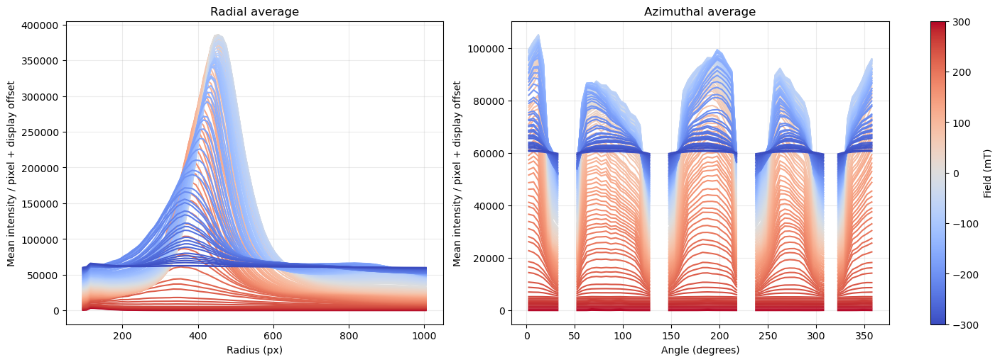

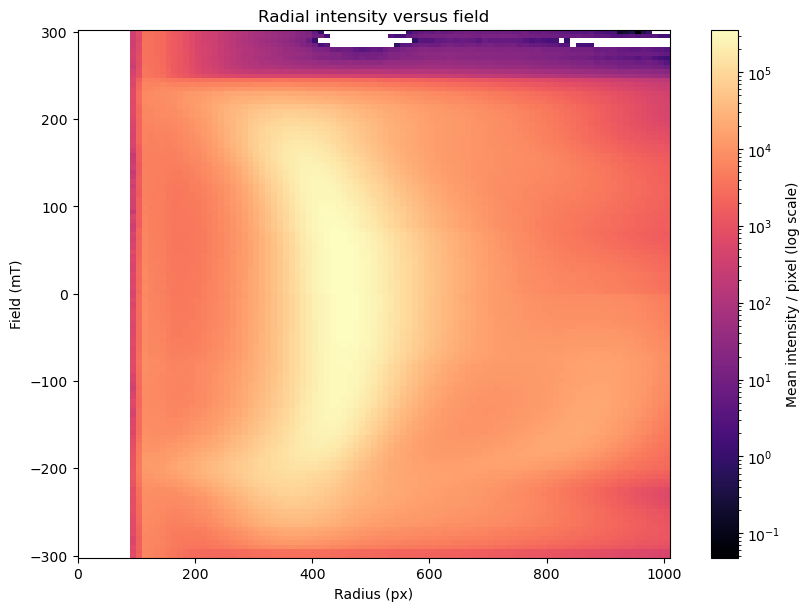

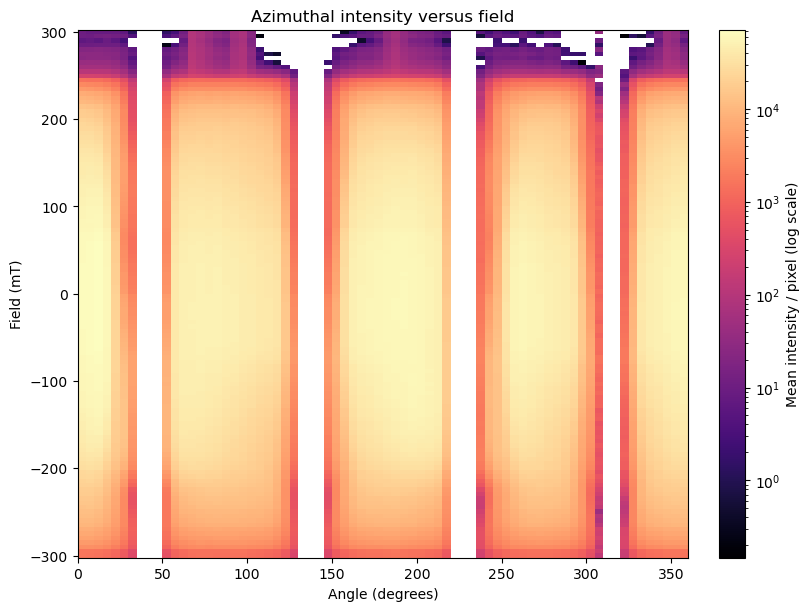

In [ ]:
# 9. Line plots and intensity maps versus field
line_figure, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
line_cmap = plt.get_cmap("coolwarm")
field_min, field_max = float(np.min(fields)), float(np.max(fields))
field_norm = plt.Normalize(field_min, field_max if field_max > field_min else field_min + 1)
# Offsets follow scan order; colors still represent the actual field.
for curve_index, (field, radial, azimuthal) in enumerate(zip(fields, radial_profiles, azimuthal_profiles)):
    color = line_cmap(field_norm(field))
    axes[0].plot(radii, radial + curve_index * radial_offset, color=color)
    axes[1].plot(angles, azimuthal + curve_index * azimuthal_offset, color=color)
axes[0].set(title="Radial average", xlabel="Radius (px)", ylabel="Mean intensity / pixel + display offset")
axes[1].set(title="Azimuthal average", xlabel="Angle (degrees)", ylabel="Mean intensity / pixel + display offset")
for ax in axes:
    ax.grid(alpha=0.25)
line_figure.colorbar(plt.cm.ScalarMappable(norm=field_norm, cmap=line_cmap),
                     ax=list(axes), label=f"{scan_label} ({field_unit})")
plt.show()

# Sort only the maps by field. GIFs and line plots keep the original order.
# Bin edges keep nonuniform field spacing accurate. Use distinct field values.
order = np.argsort(fields)
sorted_fields = np.asarray(fields)[order]
if len(fields) == 1:
    field_edges = np.array([sorted_fields[0] - 0.5, sorted_fields[0] + 0.5])
else:
    if np.any(np.diff(sorted_fields) == 0):
        raise ValueError("Use distinct fields for the maps, or analyze repeated sweeps separately")
    middle = (sorted_fields[:-1] + sorted_fields[1:]) / 2
    field_edges = np.r_[sorted_fields[0] - (middle[0] - sorted_fields[0]), middle,
                        sorted_fields[-1] + (sorted_fields[-1] - middle[-1])]
radial_figure, ax = plt.subplots(figsize=(8, 6), constrained_layout=True)
artist = ax.pcolormesh(radial_edges, field_edges, np.ma.masked_less_equal(radial_profiles[order], 0), shading="flat",
                       cmap="magma", norm=LogNorm(vmin=radial_mi, vmax=radial_ma))
ax.set(xlabel="Radius (px)", ylabel=f"{scan_label} ({field_unit})", title=f"Radial intensity versus {scan_label.lower()}")
radial_figure.colorbar(artist, ax=ax, label="Mean intensity / pixel (log scale)")
plt.show()
azimuthal_figure, ax = plt.subplots(figsize=(8, 6), constrained_layout=True)
artist = ax.pcolormesh(angular_edges, field_edges, np.ma.masked_less_equal(azimuthal_profiles[order], 0), shading="flat",
                       cmap="magma", norm=LogNorm(vmin=azimuthal_mi, vmax=azimuthal_ma))
ax.set(xlabel="Angle (degrees)", ylabel=f"{scan_label} ({field_unit})", title=f"Azimuthal intensity versus {scan_label.lower()}")
azimuthal_figure.colorbar(artist, ax=ax, label="Mean intensity / pixel (log scale)")
plt.show()

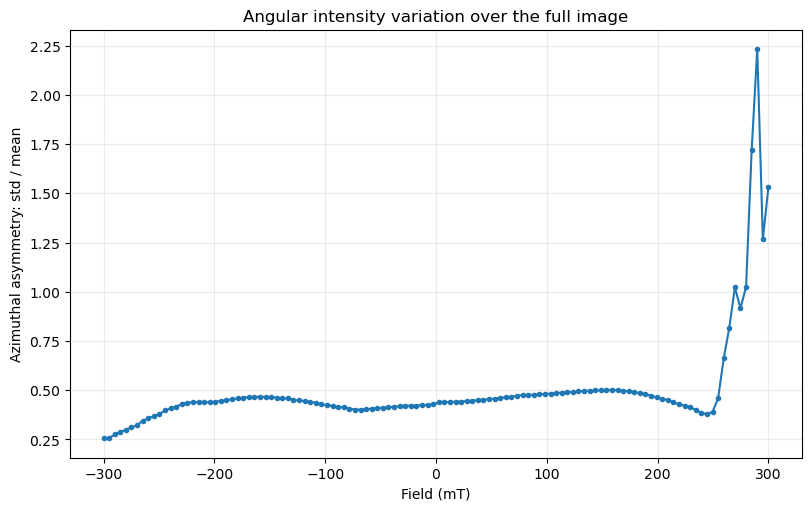

In [ ]:
# 9b. Azimuthal asymmetry versus field or energy (no display offsets)
asymmetry_figure, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
ax.plot(fields, asymmetry, "o-", markersize=3)
ax.set(xlabel=f"{scan_label} ({field_unit})", ylabel="Azimuthal asymmetry: std / mean",
       title="Angular intensity variation over the full image")
ax.grid(alpha=0.25)
plt.show()

In [ ]:
# 10. Save plots and numerical results
line_figure.savefig(output_folder / f"average_lineplots_{output_range}.png", dpi=180)
radial_figure.savefig(output_folder / f"radial_vs_field_{output_range}.png", dpi=180)
azimuthal_figure.savefig(output_folder / f"azimuthal_vs_field_{output_range}.png", dpi=180)
asymmetry_figure.savefig(output_folder / f"azimuthal_asymmetry_{output_range}.png", dpi=180)
np.savetxt(azimuthal_folder / f"asymmetry_{output_range}.csv",
           np.c_[ims, fields, asymmetry, azimuthal_mean, azimuthal_std], delimiter=",",
           header=f"scan_index,scan_value_{field_unit},std_over_mean,angular_mean,angular_std", comments="")
# Data arrays retain scan order, not sorted-map order; no display normalization.
np.savez(radial_folder / f"radial_profiles_{output_range}.npz",
         indices=ims, fields=fields, radii=radii, radial_profiles=radial_profiles,
         radial_pixel_counts=radial_counts, radial_edges=radial_edges,
         map_order=order, field_edges=field_edges, mask=mask)
np.savez(azimuthal_folder / f"azimuthal_profiles_{output_range}.npz",
         indices=ims, fields=fields, angles=angles, azimuthal_profiles=azimuthal_profiles,
         azimuthal_pixel_counts=azimuthal_counts, angular_edges=angular_edges,
         asymmetry=asymmetry, azimuthal_mean=azimuthal_mean, azimuthal_std=azimuthal_std,
         common_angular_bins=common_angular_bins,
         map_order=order, field_edges=field_edges, mask=mask)
for index, field, radial, azimuthal, rc, ac in tqdm(
        zip(ims, fields, radial_profiles, azimuthal_profiles, radial_counts, azimuthal_counts),
        total=len(ims), desc="Saving profiles", unit="scan"):
    np.savetxt(radial_folder / f"scan_{index:04d}_radial_{output_range}.csv", np.c_[radii, radial, rc],
               delimiter=",", header="radius_px,mean_intensity,valid_pixels", comments="")
    np.savetxt(azimuthal_folder / f"scan_{index:04d}_azimuthal_{output_range}.csv", np.c_[angles, azimuthal, ac],
               delimiter=",", header="angle_deg,mean_intensity,valid_pixels", comments="")
settings = dict(detector=detector, indices=ims.tolist(), fields=fields.tolist(), field_unit=field_unit,
                input_folder=str(input_folder), image_key=image_key, failed_indices=failed_indices,
                dark_scan_index=dark_scan_index,
                center_xy=[center_x, center_y], radial_bin_width=radial_bin_width,
                radial_max=radial_max, annulus=[annulus_inner, annulus_outer],
                angular_bin_width=angular_bin_width, mi=mi, ma=ma,
                asymmetry_metric="population std / mean of common azimuthal bins",
                asymmetry_min_pixels=asymmetry_min_pixels, asymmetry_min_coverage=asymmetry_min_coverage,
                radial_offset=radial_offset, azimuthal_offset=azimuthal_offset,
                radial_limits=[radial_mi, radial_ma], azimuthal_limits=[azimuthal_mi, azimuthal_ma],
                mask_path=str(mask_path) if mask_path is not None else None,
                frame_duration_ms=frame_duration_ms, gif_percentiles=gif_percentiles,
                log_gif_percentiles=log_gif_percentiles,
                frame_limits=np.asarray(frame_limits).tolist(),
                log_frame_limits=np.asarray(log_frame_limits).tolist(),
                center_image_index=center_image_index, circle_radii=circle_radii,
                normalization="intensity per valid pixel; exposures averaged; mean dark subtracted if selected")
(output_folder / f"settings_{output_range}.json").write_text(json.dumps(settings, indent=2) + "\n")
print("Plots, GIFs and settings:", output_folder.resolve())
print("Radial data:", radial_folder.resolve())
print("Azimuthal data:", azimuthal_folder.resolve())

Saving profiles:   0%|          | 0/120 [00:00<?, ?scan/s]

Plots, GIFs and settings: /Users/riccardo/Github/SEXTANTS_261105/output/cmos
Radial data: /Users/riccardo/Github/SEXTANTS_261105/output/cmos/radial
Azimuthal data: /Users/riccardo/Github/SEXTANTS_261105/output/cmos/azimuthal
